In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops

import pandas as pd

import sys
import os

# Add the parent directory to sys.path
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)

import matplotlib.gridspec as gridspec

#plt.style.use('ggplot')
# plt.style.use('seaborn-v0_8-ticks')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])


method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "dotted",
    "FLSQR-I": "dotted",
    "FLSQR-R": "dashed",
    "FLSQR-W": "dashdot",
    "IRW-FLSQR": (0, (3, 1, 1, 1, 1, 1)),
}


from trips.utilities.weights import smoothed_holder_weights


# from fsolver import IASFGK, MMFGK, MM2019FGK # VanillaFK
# from pgkbsolver import MMGKB, IASGKB, MM2019GKB
# from f2019solver import MM2019FGK2019, IASFGK2019


from msolver import VanillaGKS

from msolver import MMGKS

from pgkbsolver import MMGKB

from fsolver import MMFGK

from f2019solver import MMFGK2019

from fIRWsolver import MMFGKIRW


# What methods to do this for?
# S-GKS
# PS-GKS
# PS-GKB
# FGK
# IRW-FLSQR
# FLSQR-I
# FLSQR-R

# Setup problem data

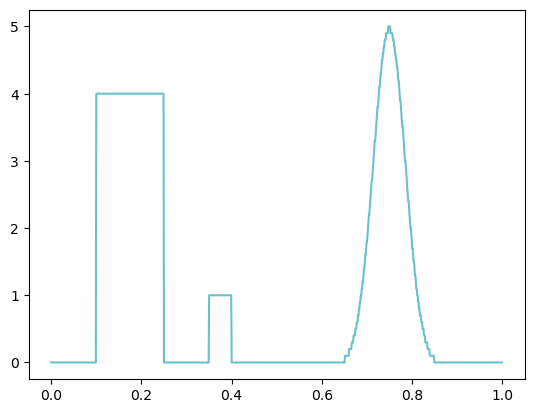

In [2]:
n = 1000

dom = np.linspace(0,1,n)

def func(x):
    if x <= 0.1:
        return 0
    elif (x > 0.1) and (x <= 0.25):
        return 40
    elif (x > 0.25) and (x <= 0.35):
        return 0
    elif (x > 0.35) and (x <= 0.4):
        return 10
    elif (x > 0.4) and (x <= 0.5):
        return 0
    elif (x > 0.5):
        return 20*np.sqrt(2*np.pi)*np.exp(- ( (x - 0.75)/0.05  )**2 )

vecfunc = np.vectorize(func)

ground_truth = vecfunc(dom)/10.0

plt.plot(dom, ground_truth)
plt.show()

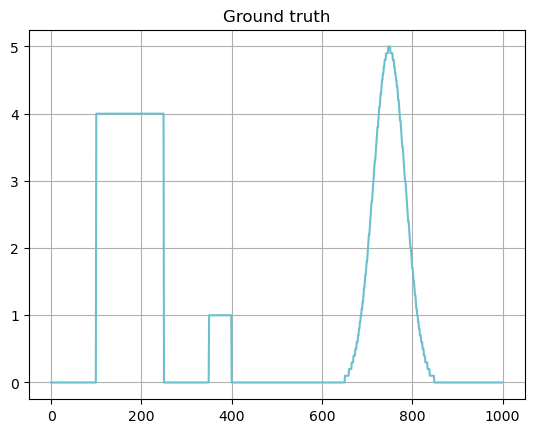

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


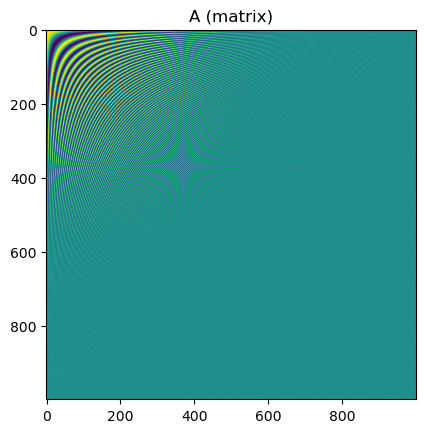

In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [6]:
# Only first 50 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [7]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

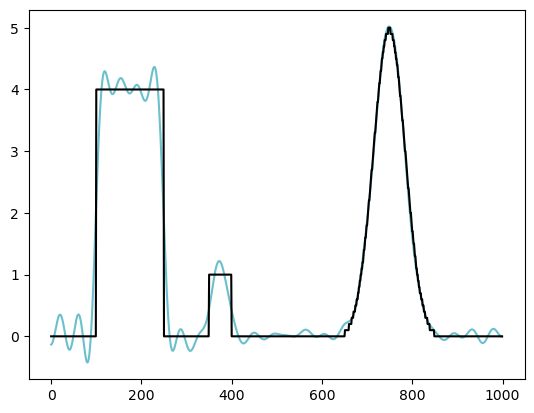

In [8]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [9]:
# Parameters
method = "dp"
n_its = 125
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7

fgk_breakdown_tol = 1e-25

In [10]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="zero")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
K = None
xker = None

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.inv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))
Lpinv_factory2 = lambda wr: jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

# Vanilla GKS
v_gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

v_gks_data = v_gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=ground_truth, weight_params={}, ksparsity=ksparsity,
                                    regparam_kwargs={"eta":1.01},  xker=xker)


epsilons = np.logspace(-12, 2, 10*14)
# epsilons = [ 1e2, 1e1, 1e0, 1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10 ]
all_data = []
for epsilon in epsilons:

    mm_weight_params = {
        "epsilon": epsilon,
        "q": 1.0,
    }

    mm_gks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


    # S-GKS
    mm_sgks_data = mm_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                        regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params,
                                        regparam_kwargs={"eta":1.01}, min_dim=None, max_dim=None, xker=xker)
    
    # PS-GKS
    mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 regparam_kwargs={"eta":1.01})
    
    # PS-GKB
    mm_psgkb_solver = MMGKB(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

    mm_psgkb_data = mm_psgkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )
    
    # FGK
    mm_fgk_solver = MMFGK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
    mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, 
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 )


    # IRW-FLSQR
    mm_fgkirw_solver = MMFGKIRW(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Option IRW

    mm_fgkIRW_data = mm_fgkirw_solver.solve(n_iter=n_its, mode="IRW", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                    regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                    #  regparam_kwargs={"eta":1.01},
                                                    lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                    #  init_dim=5
                                                    )


    # FLSQR-I, R, and W
    mm_fgk2019_solver = MMFGK2019(A, L, _Lpinv, b, noise_var=noise_var, K=K) # Options I, R, W

    mm_fgk2019I_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="I", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-R
    mm_fgk2019R_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="R", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    # FLSQR-W
    mm_fgk2019W_data = mm_fgk2019_solver.solve(n_iter=n_its, mode="W", x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
                                                 regparam=method, x_true=ground_truth, ksparsity=ksparsity, weight_params=mm_weight_params, refresh_basis=False,
                                                #  regparam_kwargs={"eta":1.01},
                                                 lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                #  init_dim=5
                                                 )


    all_data.append( (epsilon, mm_sgks_data, mm_psgks_data, mm_psgkb_data, mm_fgk_data, mm_fgkIRW_data, mm_fgk2019I_data, mm_fgk2019R_data, mm_fgk2019W_data)  ) 





745.4591398035278
475.0802647865714


306.6628713753456
288.9773905552326
284.35866291804473
282.2439344635911
281.0839102424237
280.22454832584236
279.43538237842085
278.74404570943676
278.1613663928932
277.7200986469814
277.39513121295545
277.17304328574676
277.0108564797258
276.88342973409704
276.7828169849789
276.7069345052612
276.6569453935221
276.6210329101085
276.59673505595987
276.5792608074804
276.5675646872052
276.5601298132196
276.55528975830083
276.5510650248787
276.5483067744879
276.54676447026276
276.54617954440033
276.54604624690705
276.54620586138054
276.5466599892784
276.5472625997595
276.5478799622466
276.5484815399721
276.5490708305066
276.549559071449
276.550020637847
276.55039631617274
276.5506654136655
276.5508744637792
276.5509877449263
276.5510229749258
276.55103266436686
276.5510117798905
276.5509727101127
276.55092304992263
276.550866268643
276.55081653197607
276.55076699791476
276.5507180593078
276.5506715239119
276.5506356392624
276.5506121988916
276.55059831733587
276.5505896489986
276.55058603

16.491212384165134
16.565985583521122
16.08049277319746
18.20133359150922
17.39242741834634
18.07216060307811
20.072880004928372
18.54793138054078
18.663038454236613
18.361959175019912
20.04669722386275
19.091767990648087
20.199670298878637
19.63538343178391
18.589250272645497
17.345058372908202
18.644887865516235
20.77273408449401
19.211324589195055
18.18333211415309
17.18619784439826
17.451325988409515
17.880772445045846
18.80971431318735
19.436773758487426
18.07361871739321
17.046110305390368
17.79637523086148
17.50819988469169
16.22896868259001
16.051680401442297
17.3586260129028
18.1677142306055
17.715725685506545
17.102507455102845
17.473576600258006
17.194195642455245
17.07001222586044
17.03818404714568
17.631888232569885
17.42292707939087
17.505114169885257
18.229030346544675
18.248111840253937
18.302880715443713
17.747379520063514
17.800975490935496
18.08220571841472
18.037322924049683
18.00471805536891
17.719854298961835
17.982395993519074
18.65712694755597
19.003661752490096

1e-07


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


...

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
1e-07
Starting iteration 10
1e-07
Starting iteration 11
1e-07
Starting iteration 12
11808.08235195528
Starting iteration 13
21301.593803975255
Starting iteration 14
25521.270713700076
Starting iteration 15
26749.041834182615
Starting iteration 16
27360.370180033577
Starting iteration 17
27583.128395489683
Starting iteration 18
27634.492730353628
Starting iteration 19
27647.944705765305
Starting iteration 20
27653.337091464593
Starting iteration 21
27654.33604298363
Starting iteration 22
27654.848305411542
Starting iteration 23
27655.039419434608
Starting iteration 24
27655.077454096587
Starting iteration 25
27655.086201735074
Starting iteration 26
27655.08821211206
Starting iteration 27
27655.088791900664
Starting iteration 28

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
1e-07
Starting iteration 10
1e-07
Starting iteration 11
1e-07
Starting iteration 12
11889.90308877607
Starting iteration 13
21305.26743268825
Starting iteration 14
25513.965850160846
Starting iteration 15
26744.522536527922
Starting iteration 16
27358.71922305425
Starting iteration 17
27583.1209374428
Starting iteration 18
27634.389536297364
Starting iteration 19
27648.125559132273
Starting iteration 20
27653.329751076082
Starting iteration 21
27654.34530751759
Starting iteration 22
27654.845636268084
Starting iteration 23
27655.051334705047
Starting iteration 24
27655.081845572786
Starting iteration 25
27655.092628770508
Starting iteration 26
27655.09212069374
Starting iteration 27
27655.092689150366
Starting iteration 28
276

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
1e-07
Starting iteration 10
1e-07
Starting iteration 11
1e-07
Starting iteration 12
11885.890561042681
Starting iteration 13
21346.39237933971
Starting iteration 14
25571.495032871226
Starting iteration 15
26801.98985055033
Starting iteration 16
27415.97597320081
Starting iteration 17
27639.71373325102
Starting iteration 18
27691.07758404023
Starting iteration 19
27704.5222783364
Starting iteration 20
27709.93984238857
Starting iteration 21
27710.93631391347
Starting iteration 22
27711.450924017998
Starting iteration 23
27711.640959459608
Starting iteration 24
27711.677341467985
Starting iteration 25
27711.686818875492
Starting iteration 26
27711.68938582606
Starting iteration 27
27711.68981490945
Starting iteration 28
27711.6

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
1e-07
Starting iteration 10
1e-07
Starting iteration 11
1e-07
Starting iteration 12
118.6075016103191
Starting iteration 13
213.0134695741119
Starting iteration 14
255.17529722667072
Starting iteration 15
267.4692379628799
Starting iteration 16
273.5958083781929
Starting iteration 17
275.8308477962853
Starting iteration 18
276.34390359180657
Starting iteration 19
276.4800167796028
Starting iteration 20
276.5330516369533
Starting iteration 21
276.5431920579069
Starting iteration 22
276.5481767821582
Starting iteration 23
276.550212187564
Starting iteration 24
276.5505282825593
Starting iteration 25
276.550628245039
Starting iteration 26
276.55063918444773
Starting iteration 27
276.5506436050182
Starting iteration 28
276.5506448

Starting iteration 0
1e-07
Starting iteration 1
1e-07
Starting iteration 2
1e-07
Starting iteration 3
1e-07
Starting iteration 4
1e-07
Starting iteration 5
1e-07
Starting iteration 6
1e-07
Starting iteration 7
1e-07
Starting iteration 8
1e-07
Starting iteration 9
1e-07
Starting iteration 10
1e-07
Starting iteration 11
1e-07
Starting iteration 12
11860.762307221883
Starting iteration 13
21301.368096283808
Starting iteration 14
25517.554156934126
Starting iteration 15
26746.949394619944
Starting iteration 16
27359.607020676627
Starting iteration 17
27583.11110911815
Starting iteration 18
27634.4166542956
Starting iteration 19
27648.02796515384
Starting iteration 20
27653.33143627973
Starting iteration 21
27654.345476429513
Starting iteration 22
27654.84395051752
Starting iteration 23
27655.047494648705
Starting iteration 24
27655.07910157535
Starting iteration 25
27655.089097510056
Starting iteration 26
27655.090190926
Starting iteration 27
27655.09063276762
Starting iteration 28
27655.0

In [13]:
sgks_rres = []
psgks_rres = []
psgkb_rres = []
psfgk_rres = []
fgkirw_rres = []
flsqrI_rres = []
flsqrR_rres = []
flsqrW_rres = []

sgks_gini = []
psgks_gini = []
psgkb_gini = []
psfgk_gini = []
fgkirw_gini = []
flsqrI_gini = []
flsqrR_gini = []
flsqrW_gini = []

sgks_conds = []
psgks_conds = []
psgkb_conds = []
psfgk_conds = []
fgkirw_conds = []
flsqrI_conds = []
flsqrR_conds = []
flsqrW_conds = []



for item in all_data:
    epsilon, sgks_data, psgks_data, psgkb_data, psfgk_data, fgkirw_data, flsqrI_data, flsqrR_data, flsqrW_data = item
    
    sgks_rres.append(sgks_data["rre_history"][-1])
    psgks_rres.append(psgks_data["rre_history"][-1])
    psgkb_rres.append(psgkb_data["rre_history"][-1])
    psfgk_rres.append(psfgk_data["rre_history"][-1])

    fgkirw_rres.append(fgkirw_data["rre_history"][-1])
    flsqrI_rres.append(flsqrI_data["rre_history"][-1])
    flsqrR_rres.append(flsqrR_data["rre_history"][-1])
    flsqrW_rres.append(flsqrW_data["rre_history"][-1])

    metric = "gini_indices"
    sgks_gini.append(sgks_data[metric][-1])
    psgks_gini.append(psgks_data[metric][-1])
    psgkb_gini.append(psgkb_data[metric][-1])
    psfgk_gini.append(psfgk_data[metric][-1])

    fgkirw_gini.append(fgkirw_data[metric][-1])
    flsqrI_gini.append(flsqrI_data[metric][-1])
    flsqrR_gini.append(flsqrR_data[metric][-1])
    flsqrW_gini.append(flsqrW_data[metric][-1])



    metric = "cond_ests"
    sgks_conds.append(sgks_data[metric][-1])
    psgks_conds.append(psgks_data[metric][-1])
    psgkb_conds.append(psgkb_data[metric][-1])
    psfgk_conds.append(psfgk_data[metric][-1])

    fgkirw_conds.append(fgkirw_data[metric][-1])
    flsqrI_conds.append(flsqrI_data[metric][-1])
    flsqrR_conds.append(flsqrR_data[metric][-1])
    flsqrW_conds.append(flsqrW_data[metric][-1])


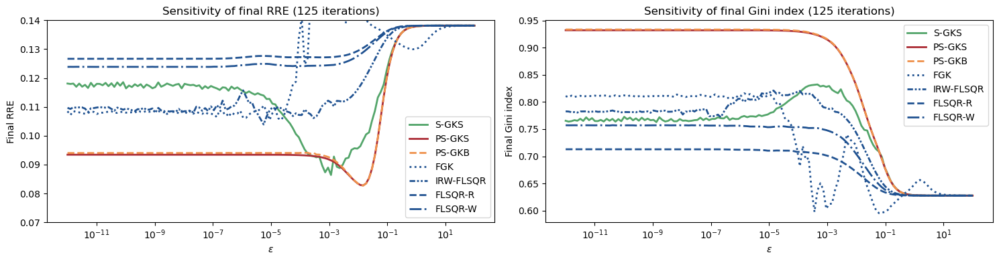

In [15]:
lw = 2.0
marker_size = 10.0

fig, axs = plt.subplots(1,2,figsize=(15,4))


axs[0].plot(epsilons, sgks_rres, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[0].plot(epsilons, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[0].plot(epsilons, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[0].plot(epsilons, psfgk_rres, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[0].scatter(epsilons, psgkb_rres, color=method_colors["FGK"], marker=method_markers["FGK"], s=marker_size)

axs[0].plot(epsilons, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[0].plot(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[0].plot(epsilons, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[0].plot(epsilons, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[0].set_xscale("log")
axs[0].set_xlabel("$\epsilon$")
axs[0].set_title("Sensitivity of final RRE (125 iterations)")
axs[0].set_ylabel("Final RRE")
axs[0].legend()









metric = "gini_indices"
axs[1].plot(epsilons, sgks_gini, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"], lw=lw)
#axs[0].scatter(epsilons, sgks_rres, color=method_colors["S-GKS"], marker=method_markers["S-GKS"], s=marker_size)

axs[1].plot(epsilons, psgks_gini, label="PS-GKS", color=method_colors["PS-GKS"], ls=method_lines["PS-GKS"], lw=lw)
#axs[0].scatter(epsilons, psgks_rres, color=method_colors["PS-GKS"], marker=method_markers["PS-GKS"], s=marker_size)

axs[1].plot(epsilons, psgkb_gini, label="PS-GKB", color=method_colors["PS-GKB"], ls="dashed",  lw=lw)
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(epsilons, psfgk_gini, label="FGK", color=method_colors["FGK"], lw=lw, ls="dotted")
#axs[1].scatter(epsilons, psgkb_rres, color=method_colors["PS-GKB"], marker=method_markers["PS-GKB"], s=marker_size)

axs[1].plot(epsilons, fgkirw_gini, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"], ls=method_lines["IRW-FLSQR"], lw=lw)
#axs[0].scatter(epsilons, fgkirw_rres, color=method_colors["IRW-FLSQR"], marker=method_markers["IRW-FLSQR"], s=marker_size)

#axs[1].plot(epsilons, flsqrI_gini, label="FLSQR-I", color=method_colors["FLSQR-I"], ls=method_lines["FLSQR-I"], lw=lw)
#axs[0].scatter(epsilons, flsqrI_rres, color=method_colors["FLSQR-I"], marker=method_markers["FLSQR-I"], s=marker_size)

axs[1].plot(epsilons, flsqrR_gini, label="FLSQR-R", color=method_colors["FLSQR-R"], ls=method_lines["FLSQR-R"], lw=lw)
#axs[0].scatter(epsilons, flsqrR_rres, color=method_colors["FLSQR-R"], marker=method_markers["FLSQR-R"], s=marker_size)

axs[1].plot(epsilons, flsqrW_gini, label="FLSQR-W", color=method_colors["FLSQR-W"], ls=method_lines["FLSQR-W"], lw=lw)
#axs[0].scatter(epsilons, flsqrW_rres, color=method_colors["FLSQR-W"], marker=method_markers["FLSQR-W"], s=marker_size)
# plt.semilogx(epsilons, psfgk_rres, label="FGK")

axs[1].set_xscale("log")
axs[1].set_xlabel("$\epsilon$")
axs[1].set_title("Sensitivity of final Gini index (125 iterations)")
axs[1].set_ylabel("Final Gini index")
axs[1].legend()


axs[0].set_ylim(0.07, 0.14)


fig.tight_layout()
fig.savefig("1d_cosine_epsilon_sensitivity.png", dpi=250, bbox_inches="tight")
fig.savefig("1d_cosine_epsilon_sensitivity.eps", format="eps", dpi=250, bbox_inches="tight")

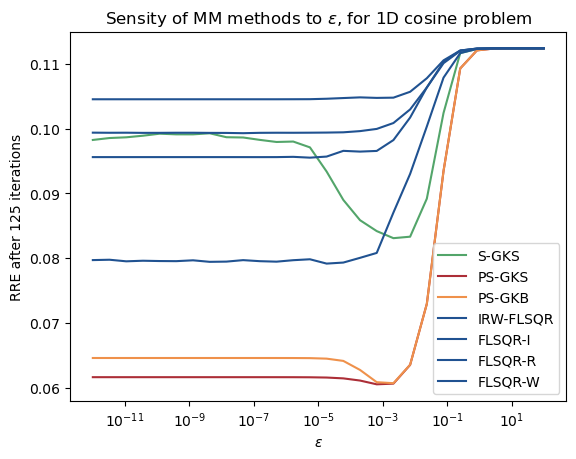

In [36]:
# plt.semilogx(epsilons, sgks_rres, label="S-GKS", color=method_colors["S-GKS"])
# plt.semilogx(epsilons, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"])
# plt.semilogx(epsilons, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"])
# #plt.semilogx(epsilons, psfgk_rres, label="FGK", color=method_colors["FGK"])
# plt.semilogx(epsilons, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"])
# plt.semilogx(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"])
# plt.semilogx(epsilons, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"])
# plt.semilogx(epsilons, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"])
# # plt.semilogx(epsilons, psfgk_rres, label="FGK")




plt.plot(epsilons, sgks_rres, label="S-GKS", color=method_colors["S-GKS"], ls=method_lines["S-GKS"])
plt.plot(epsilons, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"])
plt.plot(epsilons, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"])
#plt.plot(epsilons, psfgk_rres, label="FGK", color=method_colors["FGK"])
plt.plot(epsilons, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"])
plt.plot(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"])
plt.plot(epsilons, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"])
plt.plot(epsilons, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"])
# plt.semilogx(epsilons, psfgk_rres, label="FGK")





plt.xlabel("$\epsilon$")
plt.title("Sensity of MM methods to $\epsilon$, for 1D cosine problem")
plt.ylabel("RRE after 125 iterations")
plt.legend()
#plt.yscale("log")
plt.xscale("log")
plt.savefig("sensitivity.png", dpi=250)
plt.show()

In [ ]:
axs[plot_idx].plot( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], lw=line_width)
axs[plot_idx].scatter( grid, ias_fgk2019R_data[metric][start_idx:], color=method_colors[method], ls=method_lines[method], marker=method_markers[method], s=2*marker_size, label=method)

In [22]:
method_colors

{'GKS': 'C1',
 'S-GKS': 'C4',
 'resS-GKS': 'C4',
 'recS-GKS': 'C4',
 'PS-GKS': 'C2',
 'resPS-GKS': 'C2',
 'recPS-GKS': 'C2',
 'PS-GKB': 'C5',
 'FGK': 'C3',
 'FLSQR-I': 'C3',
 'FLSQR-R': 'C3',
 'FLSQR-W': 'C3',
 'IRW-FLSQR': 'C3'}

In [25]:
len(flsqrI_rres)

28

In [32]:
sgks_rres = []
psgks_rres = []
psgkb_rres = []
psfgk_rres = []
fgkirw_rres = []
flsqrI_rres = []
flsqrR_rres = []
flsqrW_rres = []

metric = "gini_indices"

for item in all_data:
    epsilon, sgks_data, psgks_data, psgkb_data, psfgk_data, fgkirw_data, flsqrI_data, flsqrR_data, flsqrW_data = item
    sgks_rres.append(sgks_data[metric][-1])
    psgks_rres.append(psgks_data[metric][-1])
    psgkb_rres.append(psgkb_data[metric][-1])
    psfgk_rres.append(psfgk_data[metric][-1])

    fgkirw_rres.append(fgkirw_data[metric][-1])
    flsqrI_rres.append(flsqrI_data[metric][-1])
    flsqrR_rres.append(flsqrR_data[metric][-1])
    flsqrW_rres.append(flsqrW_data[metric][-1])

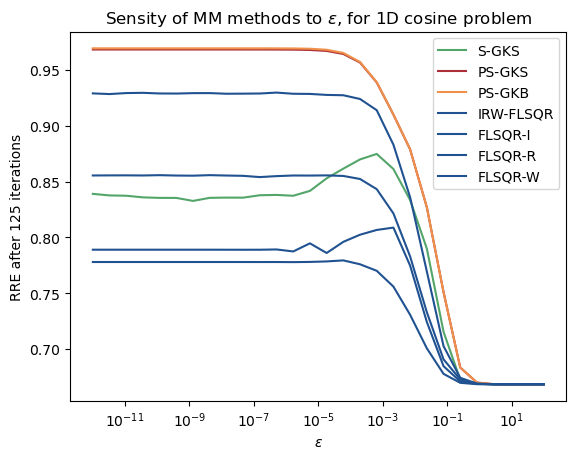

In [33]:
plt.semilogx(epsilons, sgks_rres, label="S-GKS", color=method_colors["S-GKS"])
plt.semilogx(epsilons, psgks_rres, label="PS-GKS", color=method_colors["PS-GKS"])
plt.semilogx(epsilons, psgkb_rres, label="PS-GKB", color=method_colors["PS-GKB"])
#plt.semilogx(epsilons, psfgk_rres, label="FGK", color=method_colors["FGK"])
plt.semilogx(epsilons, fgkirw_rres, label="IRW-FLSQR", color=method_colors["IRW-FLSQR"])
plt.semilogx(epsilons, flsqrI_rres, label="FLSQR-I", color=method_colors["FLSQR-I"])
plt.semilogx(epsilons, flsqrR_rres, label="FLSQR-R", color=method_colors["FLSQR-R"])
plt.semilogx(epsilons, flsqrW_rres, label="FLSQR-W", color=method_colors["FLSQR-W"])
# plt.semilogx(epsilons, psfgk_rres, label="FGK")
plt.xlabel("$\epsilon$")
plt.title("Sensity of MM methods to $\epsilon$, for 1D cosine problem")
plt.ylabel("RRE after 125 iterations")
plt.legend()
#plt.yscale("log")
#plt.savefig("sensitivity.png", dpi=250)
plt.show()